# Does G×Age interaction bias f in Model 2?

**The claim.** Parents are measured as adults and offspring as children. Suppose the two ages share only part of their genetic component, so that parents and offspring each have their own unique genetic variance. The hypothesis is that Model 2 still estimates vertical transmission f without much bias, because it captures the shared part of the genetic variance.

Model 2 here is the equilibrium SEM-PGS Cascade model with observed parental phenotypes: `UniSEMPGS_Cascade_SameTrait_ObservedYPYM.R`. It assumes one δ and one a for both generations.

**Short answer: it depends on what spouses assort on.** G×Age leaves f unbiased under social homogamy. It biases f downward under primary phenotypic AM once the unique share reaches about .2, and badly under genetic homogamy.

The table gives the relative bias of f: the mean of 30 population estimates minus the true f = .15, divided by .15 (Section 2). Every u level has its own 30 populations, so the cells are independent; the u = 0 column is the bias without G×Age.

| u (r_g) | 0 (1) | .1 (.9) | .2 (.8) | .3 (.7) | .4 (.6) | .5 (.5) |
|---|---|---|---|---|---|---|
| primary phenotypic AM | +4% | +3% | −9% | −15% | −23% | −26% |
| genetic homogamy | −5% | −8% | −36% | −51% | −105% | −138% |
| social homogamy | +7% | +6% | +3% | −2% | +3% | +5% |

One Monte Carlo SE is 3–7% of f for primary AM, 6–13% for genetic homogamy and about 3% for social homogamy.

- **Primary phenotypic AM: f is underestimated once the unique share reaches about .2.**
  - Up to u = .1 the bias is within Monte Carlo noise.
  - It is −9% at u = .2, −15% at u = .3 and −26% at u = .5.
- **Genetic homogamy: the bias is large.** It is −36% at u = .2 and −51% at u = .3. The mean estimate is about 0 at u = .4 and negative at u = .5. At u = .1 (−8%) it is still within noise.
- **Social homogamy: G×Age does not move f.**
  - The six cells scatter between −2% and +7%, with no trend in u.
  - Averaged over all 180 populations, f̂ = .156 (+3.7%, MC SE 1.4%).
  - Up to about 1 percentage point of that comes from genetic drift (Section 2).
- **Why.** Under AM, part of θNT, the path that identifies f, is AM-induced genetic covariance (2δgc + 2a·ic).
  - That part is half of θNT under primary AM, 60% under genetic homogamy and 6% under social homogamy.
  - G×Age shrinks that part in the child.
  - Model 2 captures the shared part through the PGS: δ̂ moves toward the child's value. It does not capture it through the latent score (Section 3), so it reads the remainder as weaker vertical transmission.
- **RDR helps only when it anchors the child alone (Section 4).**
  - Fixing the offspring's latent effect by the child's RDR heritability, with the parents' a estimated, removes the bias of f in all three mechanisms: within ±7% at every u.
  - Fixing both latent effects by RDR biases f by up to −37%.
  - With latent parental phenotypes, the same-trait model is more biased than Model 2 (−50% at u = .2 under primary AM). The different-trait model is less biased, but f is not identified under social homogamy.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("output")
PLOTS = OUT / "plots"; PLOTS.mkdir(parents=True, exist_ok=True)
truth = pd.read_csv(OUT / "truth" / "gxage_truth.csv")    # generating values (02_population_fits.R)
sim   = pd.read_csv(OUT / "sim_fits.csv")                # Model 2 on the GeneEvolve trios (03_fit_sim.R)
rdr   = pd.read_csv(OUT / "rdr_fits.csv")                # the RDR-anchored DiffTrait models (05_fit_rdr.R)

F_TRUE = .15
U = sorted(sim.u.unique())
MECHS = ["primary", "genetic", "social"]
MLAB  = {"primary": "primary phenotypic AM", "genetic": "genetic homogamy", "social": "social homogamy"}
# reference palette slots 1-3, with the mechanism-to-colour mapping of AMTypeCheck
COLOR = {"genetic": "#2a78d6", "social": "#eb6834", "primary": "#1baf7a"}
INK, INK2, RULE = "#0b0b0b", "#52514e", "#dcdad5"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": RULE,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": RULE,
                     "grid.linewidth": .6, "font.size": 10, "legend.frameon": False,
                     "savefig.bbox": "tight", "savefig.dpi": 150})
pd.set_option("display.width", 160, "display.max_columns", 30)

def utick(ax):
    ax.set_xticks(U)
    ax.set_xticklabels([f"{u:g}\n({1 - u:g})" for u in U])
    ax.set_xlabel("u, unique share of genetic variance\n(r_g = 1 − u)")

def endLabels(ax, ys, labels, x, dy=.012):
    # direct labels at the right end of each line, nudged apart so they do not collide
    order = np.argsort(ys); placed = []
    for i in order:
        y = ys[i]
        if placed and y - placed[-1] < dy: y = placed[-1] + dy
        placed.append(y)
        ax.annotate(labels[i], (x, ys[i]), xytext=(x + .015, y), color=INK2, fontsize=8.5, va="center",
                    annotation_clip=False)

## 1. What is simulated

**The G×Age model (common factor, symmetric).** VG0 = δ² + a² is the base-population genetic variance. Each generation's genetic value has a shared part and an age-specific part:

$$G_\text{adult} = G_\text{shared} + U_\text{adult}, \qquad G_\text{child} = G_\text{shared} + U_\text{child}, \qquad \frac{\mathrm{var}(U)}{VG_0} = u \text{ at both ages},$$

so the genetic correlation between adult and child expression is $r_g = 1 - u$. Both ages keep the same genetic variance.

| u (unique share) | 0 | .1 | .2 | .3 | .4 | .5 |
|---|---|---|---|---|---|---|
| r_g (shared share) | 1 | .9 | .8 | .7 | .6 | .5 |

**What stays the same.** The PGS carries the *adult* effects, as when it comes from an adult GWAS. Spouses assort on their adult mating phenotype. Vertical transmission comes from the parents' adult phenotypes: F = f·(Yp + Ym). The child phenotype never feeds back into later generations, so only the final generation changes. Its offspring are measured as children:

$$Y_o = r_g\,(AO + AL) + \sqrt{1 - r_g^2}\;G_U + F + E .$$

AO and AL are the adult genetic values carried by the PGS loci and the latent loci, and G_U is the child-specific genetic value.

### Simulation settings (GeneEvolve, `01_simulate.py`)

The populations are the equilibrium populations of `OpenMxScripts_Cascade/Validation/01_simulate.py`: the same engine, settings and seeds. Only the final generation's child phenotype is added.

| Setting | Value |
|---|---|
| Mating mechanisms | primary phenotypic AM, genetic homogamy, social homogamy |
| Populations | 30 per mechanism and u level (180 per mechanism): u level k (u = 0, .1, …, .5 for k = 0, …, 5) uses populations 30k + 1 … 30k + 30. Seed = 20260928 + 1000 × (0 primary, 1 genetic, 2 social) + population number |
| Population size | 10,000 individuals per generation |
| Founders (generation 0) | genotypes in Hardy–Weinberg and linkage equilibrium, F = 0, E ~ N(0, VE) |
| Generations | 30 matings with AM and VT; the offspring of the 30th mating are the children whose phenotype is G×Age |
| Causal variants | 1,000, allele frequencies ~ Uniform(.05, .50) |
| PGS / latent loci | 400 loci form the PGS and 600 the latent score (400 = 1,000 × δ² / (δ² + a²) at BASE) |
| Adult effects β_adult | N(0, 1), rescaled so the founders' PGS and latent-score variances are exactly δ² and a² |
| Assortment | on the latent mating phenotype γ̃ = AM_G·(AO + AL) + AM_E·(F + E). The target spousal correlation of γ̃ is .4 at every mating |
| Vertical transmission | F = f·(Yp + Ym) with f = .15 |
| Child-specific effects β_U | one draw per population (own random-number stream). Made orthogonal to the PGS and latent parts of β_adult (2p(1−p)-weighted), with founder variance δ² + a² |
| Child effects | β_child = r_g·β_adult + √(1 − r_g²)·β_U. Each population exports the child phenotype at its own u level only |
| Trios | one random offspring per family: 3,970–4,129 per population (mean 4,051), about 121,500 per mechanism × u when pooled |
| Data columns | Yp1, Ym1, Yo1, each centred, and the haplotypic PGS Tp1, NTp1, Tm1, NTm1 divided by δ, so a haplotype has variance k = .5 in the founders |

### Generating values

The base values are δ² = .2, a² = .3, VE = .5 and k = j = .5, so VG0 = .5 and h² = .5 in the founders. Spouses correlate .4 on γ̃ (am), and f = .15.

Within each mechanism, δ, a and VE are multiplied by one common factor so that the parents' equilibrium VY is exactly 1, as in the Validation. f and am are not rescaled.

Columns:
- **AM_G, AM_E:** the mechanism's multipliers on the genetic and on the F + E paths into γ̃.
- **µ:** the copath between spouses' γ̃.
- **gc = gt:** the AM-induced covariance between two PGS haplotypes, within and across parents.
- **ic:** the same covariance between a PGS haplotype and a latent haplotype.
- **r(Yp, Ym):** the spousal phenotypic correlation.

In [2]:
MECH_SPEC = {"primary": dict(am=.4, AM_G=1, AM_E=1), "genetic": dict(am=.4, AM_G=1, AM_E=0),
             "social":  dict(am=.4, AM_G=0, AM_E=1)}
g = (truth[(truth.u == 0) & (truth.f == F_TRUE) & truth.mating.isin(MECHS)]
     .pivot_table(index="mating", columns="quantity", values="value").reindex(MECHS))
for k in ("am", "AM_G", "AM_E"):
    g[k] = [MECH_SPEC[m][k] for m in g.index]
cols = {"delta": "δ", "a": "a", "VE": "VE", "VG0": "VG0 = δ² + a²", "f": "f", "am": "am", "AM_G": "AM_G",
        "AM_E": "AM_E", "mu": "µ", "VF": "VF", "gc": "gc = gt", "ic": "ic", "Yp_Ym": "r(Yp, Ym)"}
g[list(cols)].rename(columns=cols).rename_axis(index="mechanism", columns=None).round(3)

,δ,a,VE,VG0 = δ² + a²,f,am,AM_G,AM_E,µ,VF,gc = gt,ic,"r(Yp, Ym)"
mechanism,,,,,,,,,,,,,
primary,0.349,0.427,0.304,0.304,0.15,0.4,1,1,0.400,0.063,0.036,0.044,0.400
genetic,0.326,0.399,0.265,0.265,0.15,0.4,1,0,0.905,0.058,0.067,0.082,0.283
social,0.396,0.485,0.393,0.393,0.15,0.4,0,1,0.891,0.056,0.001,0.002,0.246


### Model 2 fits

Model 2 is fit to every population at its u level, and once to the 30 populations of each mechanism × u pooled. Each fit uses `testF` from `SensitivityAnalyses/FTestValidity/conditions.R`:
- **Mating multipliers.** AM_E is fixed at 1 and AM_G estimated (primary AM, social homogamy), or AM_G is fixed at 1 and AM_E estimated (genetic homogamy).
- **Search.** The free fit starts from the parents' true values, and again from f = −.2, 0, .1, .2 and .4 (`mxTryHard`, 5 extra tries per start). The best fit is kept.
- **Truth.** The truth for every parameter is the parents' (adult) value; f's truth is .15.

## 2. The bias of f

Each u level has its own 30 populations, so every cell is an independent estimate.
- **Bias** = the mean of the 30 population estimates minus the true f = .15. Its Monte Carlo SE is SD/√30.
- **Pooled fit:** Model 2 fit once to the 30 populations of the cell pooled, about 121,500 trios.

Because the cells are independent, each carries its own sampling error. One MC SE is about .005 (3% of f) for social homogamy, .005–.010 for primary AM and .009–.019 for genetic homogamy.

**Social homogamy.** G×Age does not change f̂ here: the six cells scatter around one value with no trend in u.
- An earlier paired run, with every u computed in the same 30 populations and archived in `output/paired/`, found every within-population change below .002.
- So the six cells are six independent estimates of one quantity. Averaged over all 180 populations, f̂ = .156 (MC SE .002, +3.7%).
- Up to about 1 percentage point of that comes from genetic drift: in a population of 10,000, the PGS haplotype variance falls slightly below the k = .5 that Model 2 fixes.
- The rest is within 2 MC SE of zero.

In [3]:
sf = sim[sim.parameter == "f11"].copy()
reps = sf[~sf.pooled]
g = reps.groupby(["mechanism", "u"])
t = pd.DataFrame({"populations": g.size(), "reps": g.rep.agg(lambda r: f"{int(r.min())}-{int(r.max())}"),
                  "mean f̂": g.estimate.mean(), "MC SE": g.estimate.std() / np.sqrt(g.size())})
t["bias"] = t["mean f̂"] - F_TRUE
t["relative bias (%)"] = 100 * t.bias / F_TRUE
t["z"] = t.bias / t["MC SE"]
t["pooled f̂"] = sf[sf.pooled].set_index(["mechanism", "u"]).estimate
t["pooled SE"] = sf[sf.pooled].set_index(["mechanism", "u"]).f_SE
print("status codes of the free fits:", sf.status_free.value_counts().to_dict())
soc = reps[reps.mechanism == "social"].estimate
print(f"social homogamy, all {len(soc)} populations: mean f̂ = {soc.mean():.4f} (MC SE {soc.std() / np.sqrt(len(soc)):.4f})")
t.reindex(MECHS, level=0).round(4).round({"relative bias (%)": 1, "z": 2})

status codes of the free fits: {1: 305, 0: 253}
social homogamy, all 180 populations: mean f̂ = 0.1555 (MC SE 0.0020)


populations     reps  mean f̂   MC SE    bias  relative bias (%)      z  pooled f̂  pooled SE
mechanism u                                                                                                 
primary   0.0           30     1-30   0.1560  0.0049  0.0060                4.0   1.23     0.1558     0.0056
          0.1           30    31-60   0.1540  0.0053  0.0040                2.7   0.76     0.1539     0.0060
          0.2           30    61-90   0.1365  0.0076 -0.0135               -9.0  -1.78     0.1370     0.0067
          0.3           30   91-120   0.1279  0.0094 -0.0221              -14.7  -2.36     0.1300     0.0079
          0.4           30  121-150   0.1149  0.0102 -0.0351              -23.4  -3.45     0.1162     0.0090
          0.5           30  151-180   0.1107  0.0088 -0.0393              -26.2  -4.45     0.1098     0.0105
genetic   0.0           30     1-30   0.1423  0.0089 -0.0077               -5.2  -0.87     0.1438     0.0080
          0.1           30    31-60   0.1373  0.0108 -0.0127               -8.5  -1.18     0.1376     0.0092
          0.2           30    61-90   0.0960  0.0124 -0.0540              -36.0  -4.37     0.0985     0.0112
          0.3           30   91-120   0.0734  0.0163 -0.0766              -51.1  -4.70     0.0742     0.0146
          0.4           30  121-150  -0.0071  0.0177 -0.1571             -104.8  -8.89    -0.0028     0.0168
          0.5           30  151-180  -0.0572  0.0193 -0.2072             -138.2 -10.76    -0.0580     0.0186
social    0.0           30     1-30   0.1602  0.0050  0.0102                6.8   2.03     0.1602     0.0046
          0.1           30    31-60   0.1583  0.0050  0.0083                5.6   1.66     0.1586     0.0048
          0.2           30    61-90   0.1551  0.0050  0.0051                3.4   1.01     0.1559     0.0050
          0.3           30   91-120   0.1471  0.0047 -0.0029               -1.9  -0.61     0.1476     0.0051
          0.4           30  121-150   0.1546  0.0050  0.0046                3.1   0.94     0.1550     0.0053
          0.5           30  151-180   0.1575  0.0051  0.0075                5.0   1.45     0.1584     0.0055

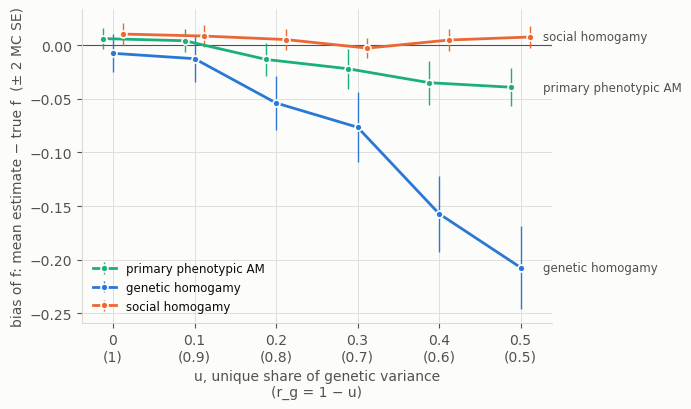

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.axhline(0, color=INK2, lw=.8)
ends = {}
for k, mech in enumerate(MECHS):
    tt = t.loc[mech].reset_index()
    ax.errorbar(tt.u + (k - 1) * .012, tt.bias, yerr=2 * tt["MC SE"], color=COLOR[mech], lw=2, marker="o", ms=5,
                mec="#fcfcfb", mew=1.2, elinewidth=1, capsize=0, label=MLAB[mech])
    ends[mech] = tt.bias.iloc[-1]
endLabels(ax, np.array([ends[m] for m in MECHS]), [MLAB[m] for m in MECHS], U[-1] + .012, dy=.02)
ax.set_ylabel("bias of f: mean estimate − true f  (± 2 MC SE)")
utick(ax)
ax.legend(loc="lower left", fontsize=8.5)
fig.tight_layout(); fig.savefig(PLOTS / "bias_f.png"); plt.show()

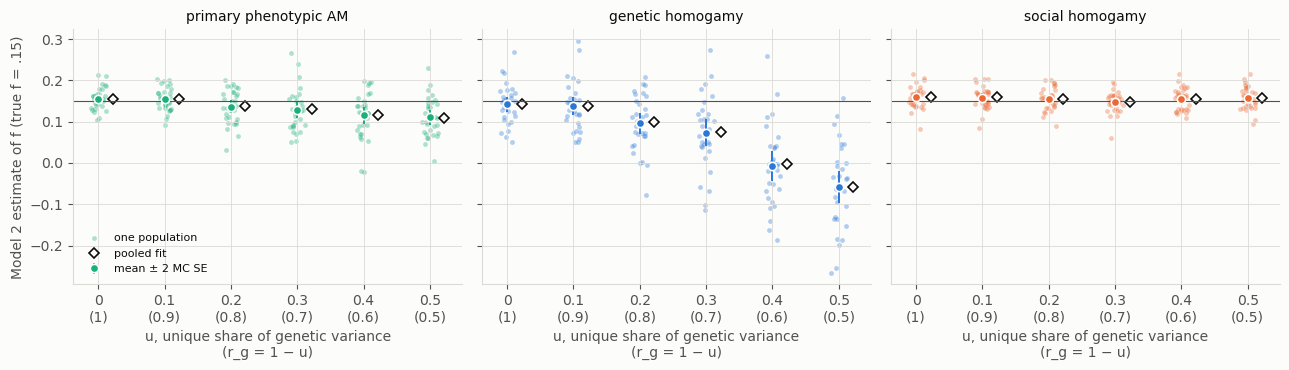

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, mech in zip(axes, MECHS):
    x = reps[reps.mechanism == mech]
    ax.scatter(x.u + np.random.default_rng(1).uniform(-.012, .012, len(x)), x.estimate, s=12, color=COLOR[mech],
               alpha=.35, lw=0, label="one population")
    tt = t.loc[mech].reset_index()
    ax.errorbar(tt.u, tt["mean f̂"], yerr=2 * tt["MC SE"], fmt="o", ms=6, color=COLOR[mech], mec="#fcfcfb", mew=1.2,
                elinewidth=1.4, capsize=0, label="mean ± 2 MC SE")
    ax.plot(tt.u + .022, tt["pooled f̂"], "D", ms=5, color=INK, mfc="#fcfcfb", mew=1.2, ls="none", label="pooled fit")
    ax.axhline(F_TRUE, color=INK2, lw=.8)
    ax.set_title(MLAB[mech], fontsize=10, color=INK)
    utick(ax)
axes[0].set_ylabel("Model 2 estimate of f (true f = .15)")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout(); fig.savefig(PLOTS / "sim_f_estimates.png"); plt.show()

## 3. Where the misspecification goes

These are the means of the 30 population estimates of each Model 2 parameter at each u (true f = .15; each u level has its own populations), next to the parents' true values. The model has one δ and one a, so G×Age has to be absorbed somewhere:
- **δ̂** moves toward the child's smaller PGS effect, r_g·δ.
- **â** shrinks much less under primary AM, and grows under genetic homogamy.
- **The mating parameters and f** take up the rest.

In [6]:
PARS = ["delta11", "a11", "VE11", "f11", "mu11", "AMGenMulti", "AMEnvMulti", "VF11", "VY11"]
x = sim[~sim.pooled & sim.parameter.isin(PARS)]
est = x.pivot_table(index=["mechanism", "parameter"], columns="u", values="estimate", aggfunc="mean")
est.columns = [f"u = {u:g}" for u in est.columns]
est.insert(0, "true (parents)", x[x.u == 0].groupby(["mechanism", "parameter"]).true.first())
est.reindex(MECHS, level=0).round(3)

true (parents)  u = 0  u = 0.1  u = 0.2  u = 0.3  u = 0.4  u = 0.5
mechanism parameter                                                                     
primary   AMGenMulti           1.000  1.052    1.196    1.377    1.713    1.970    2.379
          VE11                 0.304  0.306    0.348    0.378    0.418    0.449    0.491
          VF11                 0.063  0.070    0.067    0.055    0.050    0.043    0.037
          VY11                 1.000  0.994    0.976    0.971    0.954    0.942    0.929
          a11                  0.427  0.416    0.397    0.401    0.382    0.372    0.350
          delta11              0.349  0.341    0.318    0.290    0.260    0.235    0.199
          f11                  0.150  0.156    0.154    0.137    0.128    0.115    0.111
          mu11                 0.400  0.391    0.353    0.315    0.263    0.243    0.213
genetic   AMEnvMulti           0.000 -0.052    0.009   -0.072   -0.086   -0.252   -0.343
          VE11                 0.265  0.262    0.297    0.306    0.333    0.318    0.323
          VF11                 0.058  0.057    0.055    0.034    0.032    0.022    0.033
          VY11                 1.000  0.991    0.973    0.967    0.940    0.926    0.914
          a11                  0.399  0.401    0.385    0.408    0.401    0.443    0.458
          delta11              0.326  0.324    0.303    0.279    0.253    0.225    0.197
          f11                  0.150  0.142    0.137    0.096    0.073   -0.007   -0.057
          mu11                 0.905  0.905    0.986    1.008    1.110    0.980    0.946
social    AMGenMulti           0.000  0.016    0.007    0.048    0.069    0.124    0.136
          VE11                 0.393  0.408    0.451    0.491    0.518    0.581    0.633
          VF11                 0.056  0.066    0.064    0.061    0.055    0.060    0.062
          VY11                 1.000  0.999    0.995    0.987    0.983    0.976    0.975
          a11                  0.485  0.456    0.441    0.425    0.425    0.374    0.343
          delta11              0.396  0.396    0.361    0.318    0.287    0.245    0.200
          f11                  0.150  0.160    0.158    0.155    0.147    0.155    0.157
          mu11                 0.891  0.824    0.740    0.633    0.583    0.468    0.403

## 4. Do RDR-anchored models reduce the bias?

Two observed-parent DiffTrait Cascade models give the parents and the offspring their own δ and a, and use RDR heritability to pin a latent genetic effect. They are fit to the same 540 datasets as Model 2 (`05_fit_rdr.R`), with the same mating multipliers and the same search:
- **RDR on the child's a** (`UniSEMPGS_Cascade_DiffTrait_ObservedYPYM_EstimatedAParent.R`): RDR fixes the offspring's a_o; the parents' a_p is estimated.
- **RDR on both a** (`UniSEMPGS_Cascade_DiffTrait_ObservedYPYM_FixedAParent.R`): RDR fixes a_p and a_o.

**RDR inputs.** These are the true population values, so they carry no RDR sampling error.
- **Parents:** the adult trait's RDR heritability.
- **Child:** what RDR run on children would estimate, i.e. all of the child's genetic variance, including the child-specific part.
- **Why the child input is "too large" for the models.** They treat the child-specific part as residual, since it is unrelated to the PGS and to the parents' latent score. So the child input exceeds the value that would make them correctly specified.
- **Coding check.** At u = 0 the two values coincide, and both models then recover f = .150 exactly from the exact covariance.

In [7]:
MODEL_LAB = {"M2": "Model 2 (no RDR)", "EstA": "RDR on the child's a", "FixA": "RDR on both a"}
MODELS = list(MODEL_LAB)
rd = rdr[(rdr.parameter == "f11") & ~rdr.pooled][["model", "mechanism", "u", "rep", "estimate"]]
m2 = sim[(sim.parameter == "f11") & ~sim.pooled][["mechanism", "u", "rep", "estimate"]].assign(model="M2")
allf = pd.concat([m2, rd], ignore_index=True)
g = allf.groupby(["mechanism", "model", "u"]).estimate
cmp = pd.DataFrame({"mean": g.mean(), "MC_SE": g.std() / np.sqrt(g.size())})
cmp["bias"] = cmp["mean"] - F_TRUE
cmp["rel"] = 100 * cmp.bias / F_TRUE
h2 = rdr[rdr.parameter == "f11"].groupby(["mechanism", "u"])[["h2_RDR_parent", "h2_RDR_child"]].max()
print("RDR inputs (the parents' value is used by 'RDR on both a' only):")
display(h2.unstack("u").round(3))
print("relative bias of f (%): mean of 30 population estimates minus .15, divided by .15")
rel = cmp.rel.unstack("u").reindex(MECHS, level=0).reindex(MODELS, level=1)
display(rel.rename(index=MODEL_LAB, level=1).round(1))
print("MC SE of a mean f̂, range over u:", {MODEL_LAB[m]: f"{cmp.xs(m, level='model').MC_SE.min():.3f}-{cmp.xs(m, level='model').MC_SE.max():.3f}" for m in MODELS})

RDR inputs (the parents' value is used by 'RDR on both a' only):


h2_RDR_parent                                    h2_RDR_child                                   
u                   0.0    0.1    0.2    0.3    0.4    0.5          0.0    0.1    0.2    0.3    0.4    0.5
mechanism                                                                                                 
genetic           0.141  0.141  0.141  0.141  0.141  0.141        0.141  0.149  0.158  0.168  0.177  0.188
primary           0.185  0.185  0.185  0.185  0.185  0.185        0.185  0.193  0.201  0.210  0.219  0.229
social            0.309  0.309  0.309  0.309  0.309  0.309        0.309  0.314  0.319  0.324  0.330  0.336

relative bias of f (%): mean of 30 population estimates minus .15, divided by .15


u                               0.0   0.1   0.2   0.3    0.4    0.5
mechanism model                                                    
primary   Model 2 (no RDR)      4.0   2.7  -9.0 -14.7  -23.4  -26.2
          RDR on the child's a  3.5   4.4  -0.1  -0.2   -2.8    1.2
          RDR on both a        -1.2   0.1  -3.2  -7.5  -12.5  -16.4
genetic   Model 2 (no RDR)     -5.2  -8.5 -36.0 -51.1 -104.8 -138.2
          RDR on the child's a -4.0   2.4  -2.8   1.2   -7.0   -6.4
          RDR on both a        -9.5  10.9  11.6  10.3    8.3    6.4
social    Model 2 (no RDR)      6.8   5.6   3.4  -1.9    3.1    5.0
          RDR on the child's a  4.7   3.7   2.4  -4.6    0.3    1.8
          RDR on both a        -0.2  -7.5 -16.7 -22.2  -30.8  -37.5

MC SE of a mean f̂, range over u: {'Model 2 (no RDR)': '0.005-0.019', "RDR on the child's a": '0.004-0.008', 'RDR on both a': '0.001-0.005'}


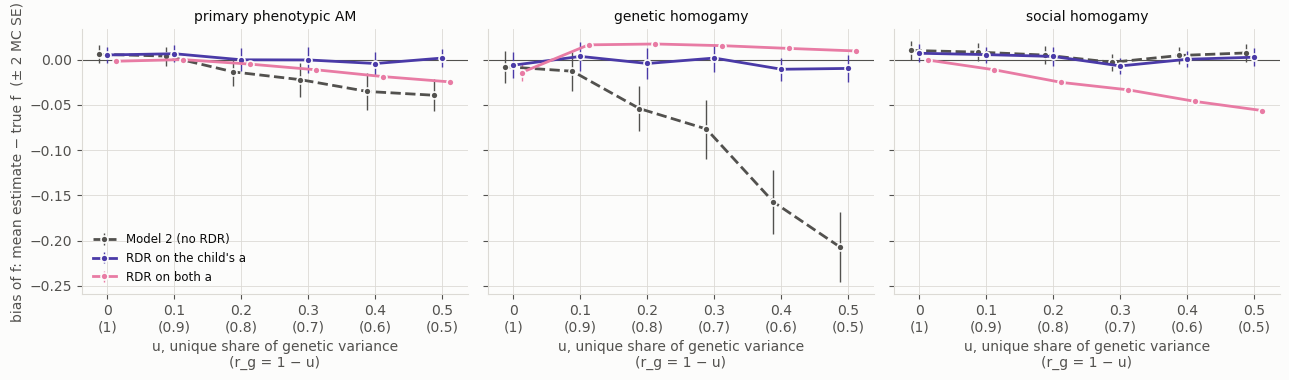

In [8]:
MCOL = {"M2": INK2, "EstA": "#4a3aa7", "FixA": "#e87ba4"}   # neutral reference + reference palette slots 7 and 5
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, mech in zip(axes, MECHS):
    ax.axhline(0, color=INK2, lw=.8)
    for k, mod in enumerate(MODELS):
        c = cmp.loc[(mech, mod)].reset_index()
        ax.errorbar(c.u + (k - 1) * .012, c.bias, yerr=2 * c.MC_SE, color=MCOL[mod], lw=2, ls="--" if mod == "M2" else "-",
                    marker="o", ms=5, mec="#fcfcfb", mew=1.2, elinewidth=1, capsize=0, label=MODEL_LAB[mod])
    ax.set_title(MLAB[mech], fontsize=10, color=INK)
    utick(ax)
axes[0].set_ylabel("bias of f: mean estimate − true f  (± 2 MC SE)")
axes[0].legend(loc="lower left", fontsize=8.5)
fig.tight_layout(); fig.savefig(PLOTS / "rdr_bias_f.png"); plt.show()

**Fixing only the child's a removes the bias of f.**
- In every mechanism and at every u, the mean f̂ stays within ±7% of .15 and within 1.7 MC SE.
- The parents' side pays for it, as the table below shows. As u grows, the child's RDR pins a_o above the parents' a, so â_p falls (primary AM: .41 at u = 0 to .20 at u = .5) and the parental residual VE_p rises. Together they keep the parent–offspring genetic covariance in line with the data, so f does not have to move.

**Fixing both a's introduces a bias of its own.**
- With a_p pinned to the parents' RDR and a_o to the child's larger RDR, only f and the mating parameters are left to absorb the mismatch.
- f̂ falls by 16% (primary AM) and 37% (social homogamy) at u = .5, and rises by 6–12% under genetic homogamy.
- With both a's fixed, the estimates are very precise (MC SE about .001 at u > 0), so these biases are far beyond noise.

**Weakly identified fits.** Two cells contain fits that run off along known weakly identified directions; f̂ in those fits is .08–.13.
- **Social homogamy, RDR on the child's a, u ≤ .1:** 5 fits run off along µ (µ̂ = 5 to 533).
- **Genetic homogamy, RDR on both a, u = 0:** about 7 fits take a negative AM_E. This makes that cell's mean f̂ low (−9%).

Mean estimates of the parental and offspring parameters (true values are the parents'; under G×Age the child's own δ and a are r_g·δ and r_g·a):

In [9]:
P2 = {"a_p11": "a_p", "a_o11": "a_o", "delta_p11": "δ_p", "delta_o11": "δ_o",
      "VE_parent": "VE_p", "VE_p11": "VE_p", "VE_offspring": "VE_o", "VE_o11": "VE_o"}
x = rdr[~rdr.pooled & rdr.parameter.isin(P2)].assign(par=lambda d: d.parameter.map(P2))
est = x.pivot_table(index=["mechanism", "model", "par"], columns="u", values="estimate", aggfunc="mean")
est.columns = [f"u = {u:g}" for u in est.columns]
est.insert(0, "true (parents)", x[x.u == 0].groupby(["mechanism", "model", "par"]).true.first())
est.reindex(MECHS, level=0).rename(index=MODEL_LAB, level=1).round(3)

true (parents)  u = 0  u = 0.1  u = 0.2  u = 0.3  u = 0.4  u = 0.5
mechanism model                par                                                                     
primary   DiffLat              VE_o           0.304  0.269    0.273    0.302    0.286    0.298    0.278
                               VE_p           0.304  0.267    0.300    0.333    0.325    0.329    0.308
                               a_o            0.427  0.446    0.465    0.475    0.500    0.509    0.530
                               a_p            0.427  0.442    0.415    0.370    0.356    0.322    0.321
                               δ_o            0.349  0.338    0.312    0.279    0.243    0.216    0.176
                               δ_p            0.349  0.344    0.348    0.372    0.377    0.395    0.394
          RDR on the child's a VE_o           0.304  0.290    0.302    0.308    0.310    0.310    0.304
                               VE_p           0.304  0.317    0.383    0.434    0.484    0.522    0.562
                               a_o            0.427  0.437    0.453    0.474    0.492    0.506    0.521
                               a_p            0.427  0.409    0.366    0.334    0.289    0.251    0.195
                               δ_o            0.349  0.340    0.312    0.277    0.242    0.213    0.175
                               δ_p            0.349  0.347    0.361    0.375    0.382    0.392    0.397
          RDR on both a        VE_o           0.304  0.296    0.307    0.310    0.316    0.318    0.317
                               VE_p           0.304  0.305    0.376    0.439    0.482    0.514    0.545
                               a_o            0.427  0.432    0.450    0.473    0.488    0.501    0.514
                               a_p            0.427  0.426    0.382    0.344    0.315    0.287    0.259
                               δ_o            0.349  0.342    0.314    0.279    0.246    0.219    0.185
                               δ_p            0.349  0.347    0.363    0.379    0.388    0.399    0.409
genetic   DiffLat              VE_o           0.265  0.262    0.262    0.271    0.270    0.276    0.267
                               VE_p           0.265  0.266    0.291    0.299    0.298    0.290    0.276
                               a_o            0.399  0.401    0.424    0.442    0.457    0.470    0.485
                               a_p            0.399  0.407    0.352    0.307    0.282    0.255    0.239
                               δ_o            0.326  0.323    0.291    0.261    0.231    0.197    0.165
                               δ_p            0.326  0.308    0.342    0.372    0.378    0.389    0.393
          RDR on the child's a VE_o           0.265  0.272    0.272    0.271    0.270    0.270    0.268
                               VE_p           0.265  0.241    0.325    0.372    0.434    0.464    0.500
                               a_o            0.399  0.396    0.418    0.441    0.457    0.471    0.484
                               a_p            0.399  0.402    0.355    0.331    0.278    0.265    0.223
                               δ_o            0.326  0.325    0.295    0.263    0.231    0.198    0.166
                               δ_p            0.326  0.318    0.343    0.363    0.377    0.393    0.403
          RDR on both a        VE_o           0.265  0.276    0.263    0.260    0.263    0.261    0.261
                               VE_p           0.265  0.224    0.366    0.419    0.464    0.495    0.525
                               a_o            0.399  0.392    0.424    0.449    0.462    0.477    0.488
                               a_p            0.399  0.420    0.330    0.288    0.249    0.215    0.179
                               δ_o            0.326  0.327    0.292    0.257    0.227    0.192    0.162
                               δ_p            0.326  0.317    0.351    0.369    0.380    0.391    0.401
social    DiffLat              VE_o           0.393  0.241    0.212    0.227    0.211

### Latent parental phenotypes

Two more RDR-anchored models use only the child's phenotype and the four PGS haplotypes: the same datasets, with Yp1 and Ym1 dropped.
- **Same trait, latent parents** (`UniSEMPGS_Cascade_SameTrait_LatentYPYM.R`): one δ and one a for both generations; the child's RDR fixes a.
- **Different traits, latent parents** (`UniSEMPGS_Cascade_DiffTrait_LatentYPYM.R`): its own δ and a for parents and child.
  - RDR fixes both a's, with the adult RDR for the parents and the child's RDR for the child.
  - µ is fixed at its true value, which the script needs for identification.
  - It assumes one VY shared by the parents' and the child's trait. G×Age violates that: the child's VY is smaller, for example .81 against 1 under primary AM at u = .5.

**Other settings.**
- **Mating mechanism.** With latent parents it is not identified, so both multipliers are fixed at the true mechanism.
- **RDR inputs.** The same true values as above.

**Coding check.** At u = 0 on the exact covariance, both models recover f = .150, with one exception. Under social homogamy, the different-trait model's f lies on a flat ridge: f = .150 and f = .156 fit equally well (−2LL within .0001).

In [10]:
LAT_LAB = {"M2": "Model 2 (no RDR)", "SameLat": "same trait, latent parents", "DiffLat": "different traits, latent parents"}
LAT = list(LAT_LAB)
gl = allf.groupby(["mechanism", "model", "u"]).estimate
lat = pd.DataFrame({"mean": gl.mean(), "median": gl.median(), "MC_SE": gl.std() / np.sqrt(gl.size())})
lat = lat[lat.index.get_level_values("model").isin(LAT)]
lat["bias"] = lat["mean"] - F_TRUE
for stat in ("mean", "median"):
    print(f"relative bias of f (%), {stat} of 30 population estimates")
    t_ = (100 * (lat[stat] - F_TRUE) / F_TRUE).unstack("u").reindex(MECHS, level=0).reindex(LAT, level=1)
    display(t_.rename(index=LAT_LAB, level=1).round(1))
print("MC SE of a mean f̂, range over u:", {LAT_LAB[m]: f"{lat.xs(m, level='model').MC_SE.min():.3f}-{lat.xs(m, level='model').MC_SE.max():.3f}" for m in LAT})

relative bias of f (%), mean of 30 population estimates


u                                            0.0   0.1   0.2    0.3    0.4    0.5
mechanism model                                                                  
primary   Model 2 (no RDR)                   4.0   2.7  -9.0  -14.7  -23.4  -26.2
          same trait, latent parents        -4.7 -20.7 -50.4  -82.9 -120.7 -180.1
          different traits, latent parents  -2.1  -2.7  -4.9   -7.7  -10.5  -12.3
genetic   Model 2 (no RDR)                  -5.2  -8.5 -36.0  -51.1 -104.8 -138.2
          same trait, latent parents        -3.4 -33.8 -73.4 -113.9 -181.6 -300.5
          different traits, latent parents -14.5   2.6  11.4    9.5    5.4    0.7
social    Model 2 (no RDR)                   6.8   5.6   3.4   -1.9    3.1    5.0
          same trait, latent parents        17.3  18.0  13.0   79.1   62.0  182.4
          different traits, latent parents  14.8  12.7  11.6    9.3    1.9   -0.3

relative bias of f (%), median of 30 population estimates


u                                            0.0   0.1   0.2    0.3    0.4    0.5
mechanism model                                                                  
primary   Model 2 (no RDR)                   3.0   1.5  -9.1  -15.3  -19.2  -30.7
          same trait, latent parents        -4.6 -21.0 -49.7  -81.0 -116.9 -175.7
          different traits, latent parents  -1.3  -2.6  -3.7   -7.1  -10.2  -12.2
genetic   Model 2 (no RDR)                  -3.0 -11.9 -34.9  -50.1 -102.7 -132.2
          same trait, latent parents        -1.5 -28.6 -71.8 -108.7 -178.6 -279.7
          different traits, latent parents  -8.7  13.3  12.6   10.3    5.7    0.7
social    Model 2 (no RDR)                  10.7   9.7   3.7   -1.3    7.1    4.3
          same trait, latent parents        20.7  20.1  13.7   33.0    4.7  -17.0
          different traits, latent parents  37.5  35.8  32.9   31.9   14.5  -10.3

MC SE of a mean f̂, range over u: {'Model 2 (no RDR)': '0.005-0.019', 'same trait, latent parents': '0.002-0.123', 'different traits, latent parents': '0.000-0.009'}


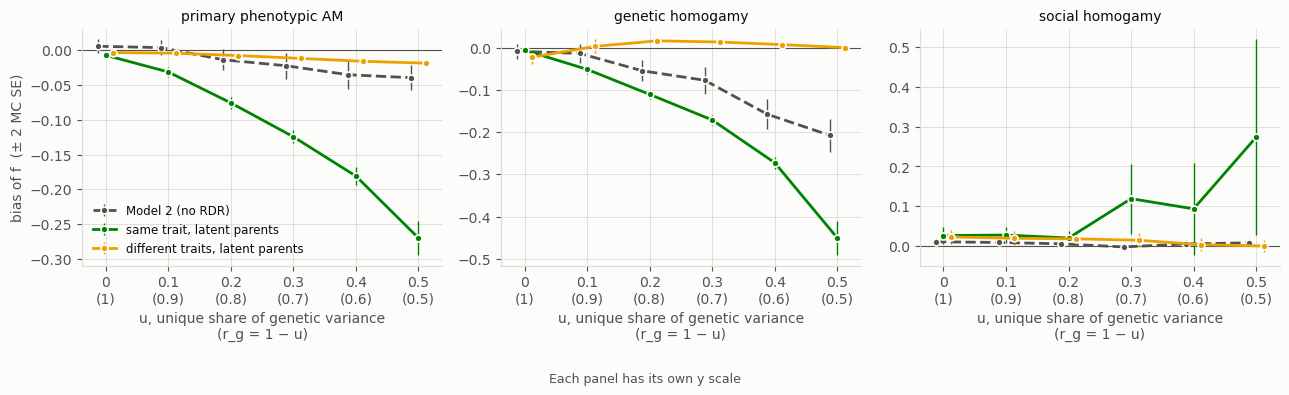

In [11]:
LCOL = {"M2": INK2, "SameLat": "#008300", "DiffLat": "#eda100"}   # neutral reference + reference palette slots 6 and 4
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, mech in zip(axes, MECHS):
    ax.axhline(0, color=INK2, lw=.8)
    for k, mod in enumerate(LAT):
        c = lat.loc[(mech, mod)].reset_index()
        ax.errorbar(c.u + (k - 1) * .012, c.bias, yerr=2 * c.MC_SE, color=LCOL[mod], lw=2, ls="--" if mod == "M2" else "-",
                    marker="o", ms=5, mec="#fcfcfb", mew=1.2, elinewidth=1, capsize=0, label=LAT_LAB[mod])
    ax.set_title(MLAB[mech], fontsize=10, color=INK)
    utick(ax)
axes[0].set_ylabel("bias of f  (± 2 MC SE)")
axes[0].legend(loc="lower left", fontsize=8.5)
fig.suptitle("Each panel has its own y scale", y=-.04, fontsize=9, color=INK2)
fig.tight_layout(); fig.savefig(PLOTS / "rdr_latent_bias_f.png"); plt.show()

**Same trait, latent parents: G×Age biases f more than in Model 2.**
- With one δ and one a for both generations, the child's RDR pins a to the child's whole genetic variance. The model can only fit the child's weaker covariance with the PGS haplotypes by lowering f.
- f̂ falls by 21% at u = .1 and by 50% at u = .2 under primary AM. It turns negative from u = .4 under primary AM and from u = .3 under genetic homogamy.
- Under social homogamy f̂ is +17% already at u = 0.
- From u = .3 on, 10–20% of the social-homogamy fits run off (µ̂ < −2, VÊ of 7–13, f̂ up to 2.4). The means there are not meaningful; the medians are .20, .16 and .13 at u = .3, .4 and .5.

**Different traits, latent parents: less bias than Model 2, but weakly identified.**
- **Primary AM:** −2% at u = 0, down to −12% at u = .5 (Model 2: −26%).
- **Genetic homogamy:** +5% to +11% at u = .2–.4 (Model 2: −36% to −105%). At u ≤ .1 a few fits reach f̂ ≈ 0, which pulls the mean at u = 0 to −14% (median −9%).
- **Social homogamy:** f is not identified. The fits split between two boundary solutions on the flat ridge from the coding check: either a_p reaches its lower bound and f̂ ≈ .09–.11, or VE_p reaches its lower bound and f̂ ≈ .21. The mean (+15% at u = 0) mixes the two.

## 5. Summary

1. **Under primary phenotypic AM, f is underestimated once the unique share reaches about .2.** The bias is within Monte Carlo noise at u ≤ .1 (r_g ≥ .9), then −9% at u = .2, −15% at u = .3 and −26% at u = .5.
2. **Under genetic homogamy, G×Age is a serious problem for f.** The bias is −36% at u = .2 and −51% at u = .3, and the mean f̂ is about 0 at u = .4.
3. **Under social homogamy, G×Age does not change f̂.** The cells scatter between −2% and +7%, with no trend in u. Over all 180 populations f̂ = .156 (+3.7%): about 1 point of it comes from drift, and the rest is within 2 MC SE of zero.
4. **Under AM, Model 2's bias points toward smaller f.**
5. **With observed parents, an RDR anchor on the child alone removes the bias.** The DiffTrait model that fixes the offspring's latent effect by the child's RDR heritability, with the parents' a estimated, keeps f within ±7% in all three mechanisms; the parents' a and VE absorb the mismatch instead. Fixing both latent effects by RDR does not help: it biases f by up to −37% (social homogamy, u = .5).
6. **With latent parents, RDR does not rescue f.**
   - The same-trait model is more biased than Model 2: −50% at u = .2 under primary AM.
   - The different-trait model is less biased (−12% at u = .5 under primary AM, within +11% under genetic homogamy), but under social homogamy f is not identified.

**Scope.**
- Equilibrium, continuous trait, f = .15, the generating values of Section 1.
- 30 independent populations per mechanism and u level: one MC SE of a mean f̂ is .001–.019, depending on the model.
- The PGS carries the adult effects.
- The age-specific genetic value is independent of the adult effects, and both ages have the same genetic variance.
- The RDR inputs are the true population values, with no RDR sampling error.
- Random mating and f = 0 were not simulated.